In [1]:
import pathlib
import xarray as xr
import helpers

In [2]:
# datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_submission/data/statistics_L1')
datadir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_submission/data/statistics_L1_test_model_change')
# outdir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_submission/data/statistics_L2')
outdir = pathlib.Path(f'/work/bb1153/b382635/plots/model_paper/grl_submission/data/statistics_L2_test_model_change')
outdir.mkdir(exist_ok=1, parents=1)
flist = sorted(list(datadir.glob('*')))

print(len(flist), 'files ready')

91 files ready


In [3]:
li = []
for f in flist:
    result_path = outdir / f.name
    # if result_path.exists():
    #     continue
    ds = xr.open_dataset(f)
    results = helpers.results_for_analyses(ds)
    results.to_netcdf(result_path)
    print('done', f.stem)

done b10s50
done b11s50
done b12s50
done b13s50
done b14s50
done b15s50
done b16s50
done b17s50
done b18s50
done b19s50
done b1s50
done b20s50
done b21s50
done b22s50
done b23s50
done b24s50
done b25s50
done b26s50
done b27s50
done b28s50
done b29s50
done b2s50
done b30s50
done b31s50
done b32s50
done b33s50
done b34s50
done b35s50
done b36s50
done b37s50
done b38s50
done b39s50
done b3s50
done b40s50
done b41s50
done b42s50
done b43s50
done b44s50
done b45s50
done b46s50
done b47s50
done b48s50
done b49s50
done b4s50
done b50s50
done b51s50
done b52s50
done b53s50
done b54s50
done b55s50
done b56s50
done b57s50
done b58s50
done b59s50
done b5s50
done b60s50
done b61s50
done b62s50
done b63s50
done b64s50
done b65s50
done b66s50
done b67s50
done b68s50
done b69s50
done b6s50
done b70s50
done b71s50
done b72s50
done b73s50
done b74s50
done b75s50
done b76s50
done b77s50
done b78s50
done b79s50
done b7s50
done b80s50
done b81s50
done b82s50
done b83s50
done b84s50
done b85s50
done b86s50

In [ ]:
# working....

In [ ]:
import global3d_track as g3d
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

ds = xr.open_dataset(flist[0])
# results = tools.collect_system_level_results(ds)

#### view preds

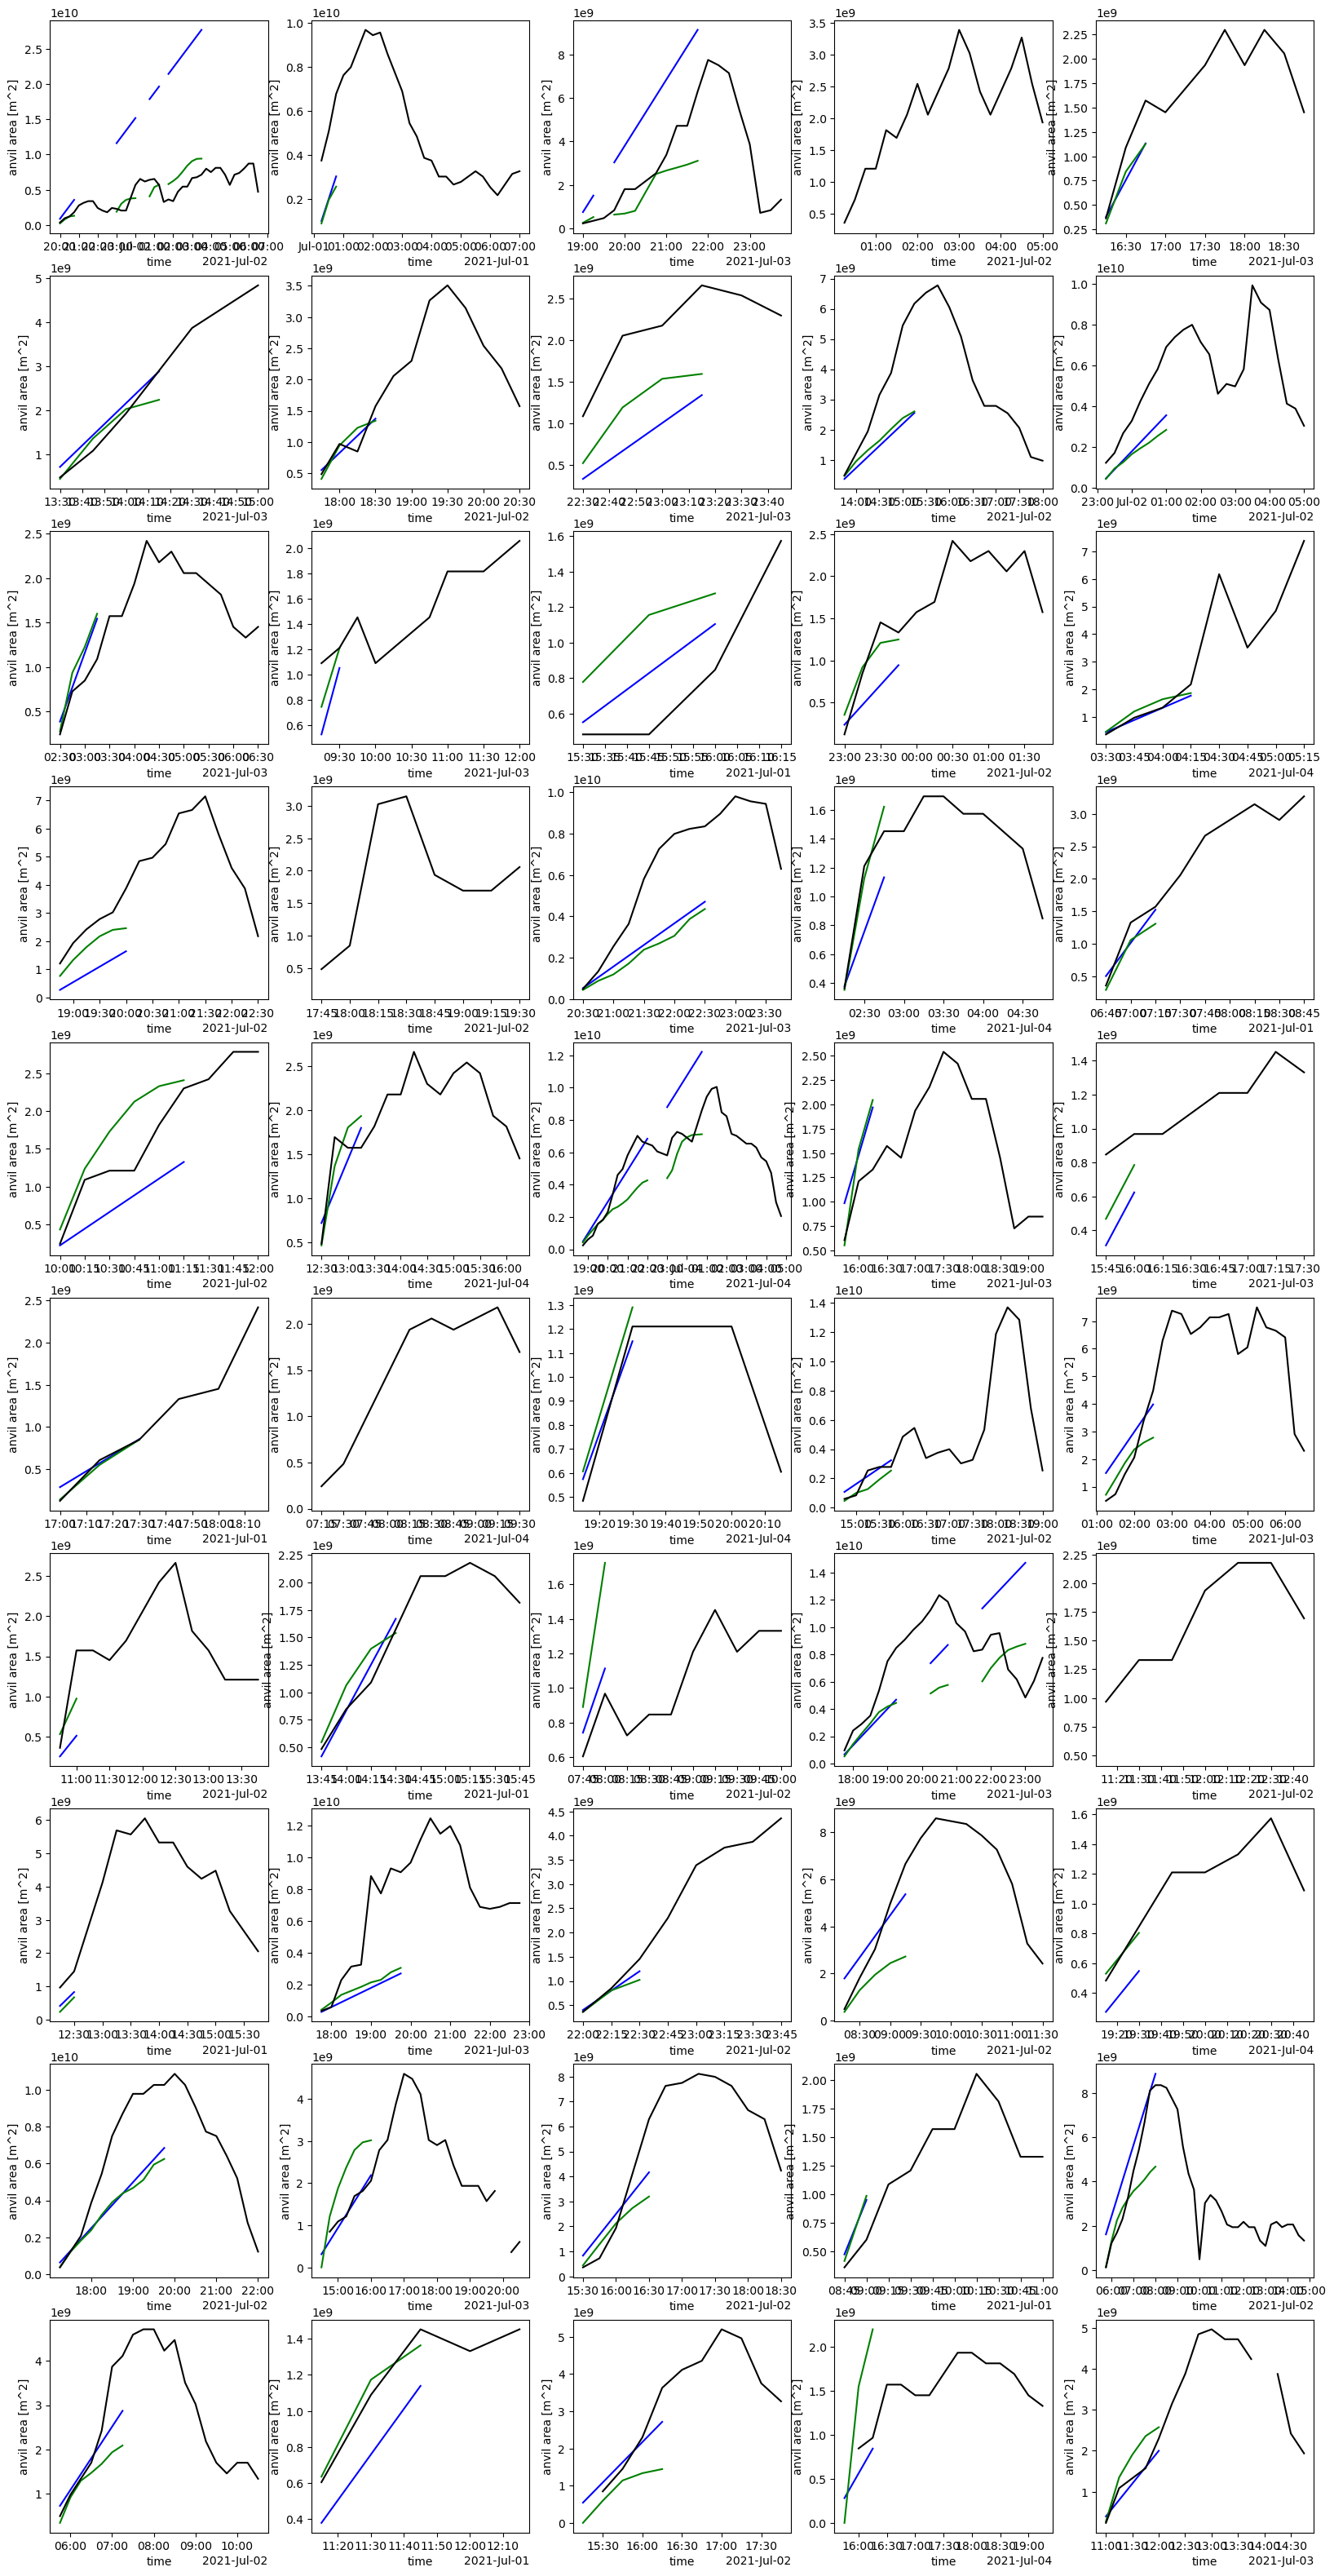

In [6]:
fig, axs = plt.subplots(10,5,figsize=(20,40))

for i,ax in enumerate(axs.flat):
    d = ds.isel(system=i)
    d.Apred_v1_conv.plot(ax=ax, c='b')
    d.Apred_v3_conv.plot(ax=ax, c='g')
    d.anvil_area.plot(ax=ax, c='k')
    ax.set(title='')

fig.savefig("/home/b/b382635/s/my_notebooks/model_paper/grl_submission/scripts/check_model_preds.jpg")

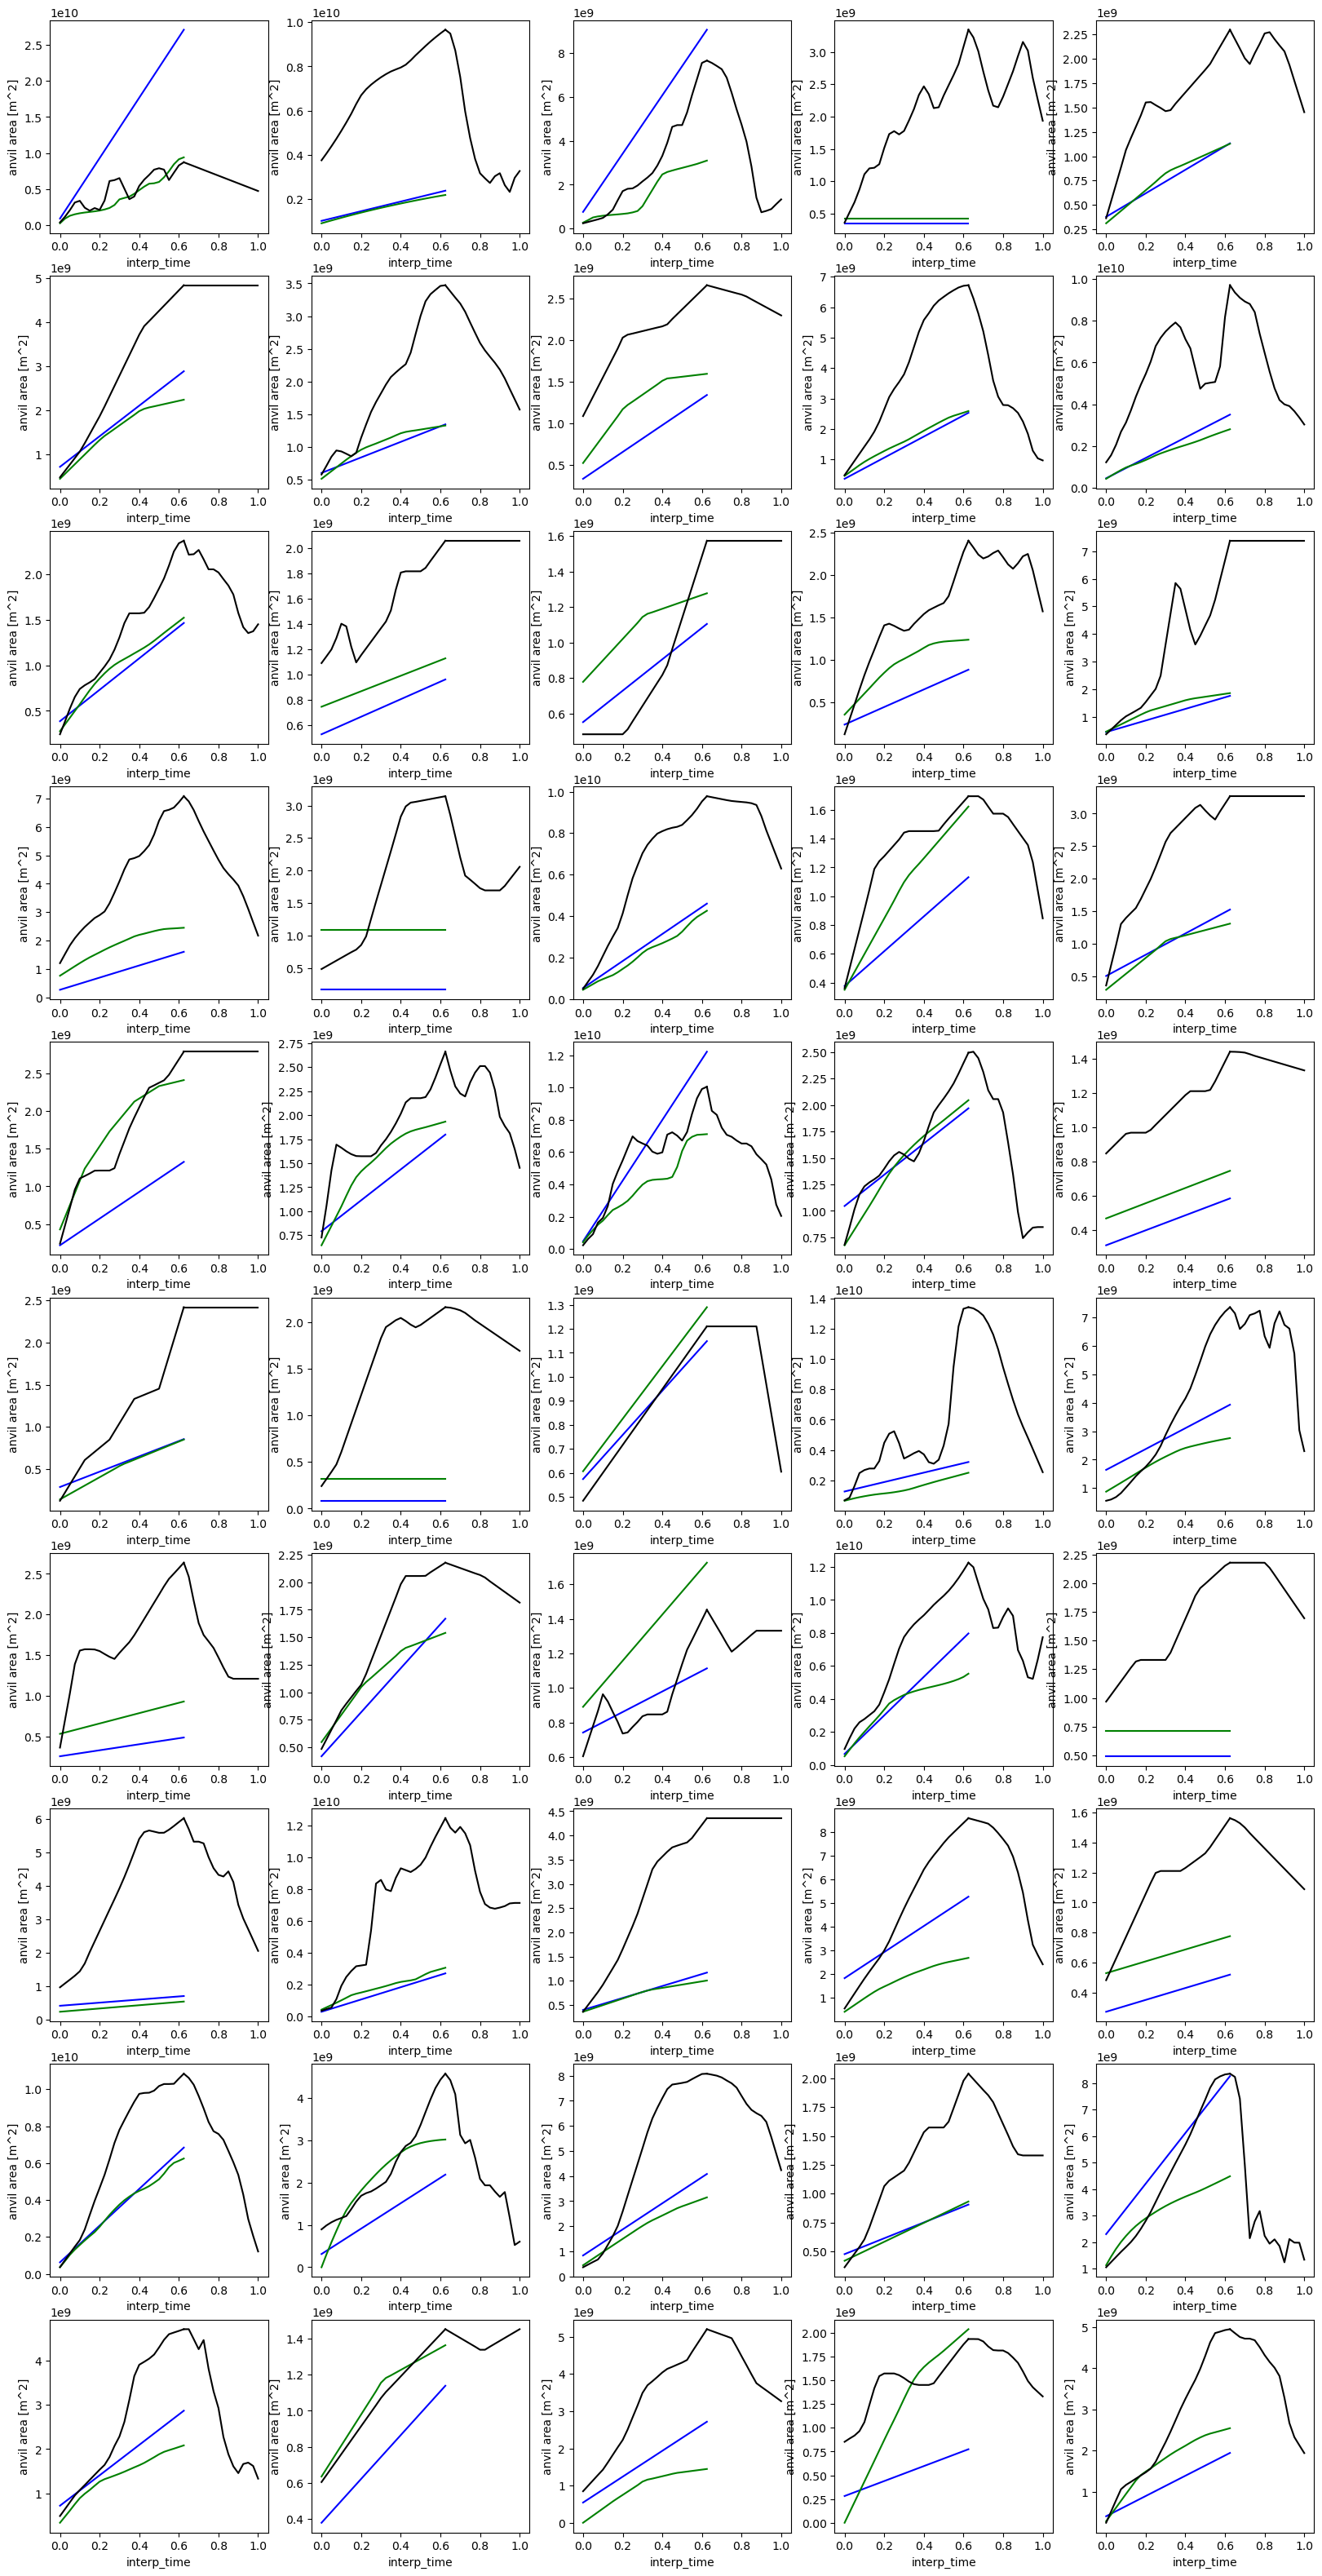

In [7]:
fig, axs = plt.subplots(10,5,figsize=(20,40))

for i,ax in enumerate(axs.flat):
    d = results.isel(system=i)
    d.sel(phase='growing').Apred_v1_conv.plot(ax=ax, c='b')
    d.sel(phase='growing').Apred_v3_conv.plot(ax=ax, c='g')
    d.sel(phase='growing').anvil_area.plot(ax=ax, c='k')
    d.sel(phase='decay').anvil_area.plot(ax=ax, c='k')
    ax.set(title='')

fig.savefig("/home/b/b382635/s/my_notebooks/model_paper/grl_submission/scripts/check_model_preds_interp.jpg")

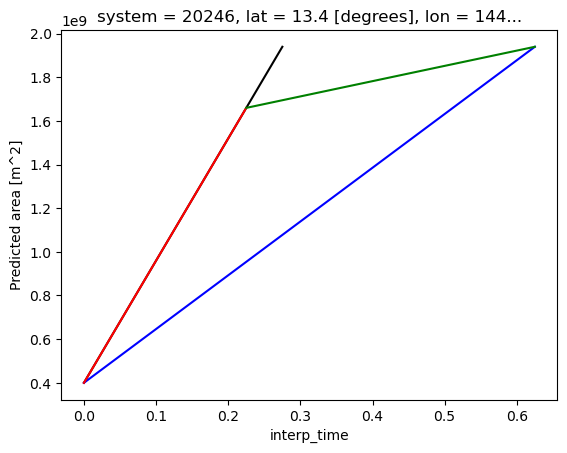

In [11]:
d.sel(phase='overall').Apred_v1_conv.plot(c='k')
d.sel(phase='growing').Apred_v1_conv.plot(c='b')
d.sel(phase='developing').Apred_v1_conv.plot(c='r')
d.sel(phase='mature').Apred_v1_conv.plot(c='g')

#### NEW INTERP

In [5]:
import datetime
import scipy

In [6]:
# define new time axis
tstep = 0.025
new_taxis = np.arange(0, 1+tstep, tstep)

In [120]:
# first interpolate the time series
dsi = tools.normalise_by_lifetime(ds.cloud_area > 0, 
                            ds[['cloud_area','cloud_depth','thick_area','Apred_v3_conv']], 
                            bins=new_taxis).rename({"interp_time":"itime"})

# identify phase transition times
t_max_depth = dsi.cloud_depth.idxmax('itime')
t_max_area = dsi.cloud_area.idxmax('itime')

# split data into lifecycle phases
developing = dsi.where(dsi.itime <= t_max_depth)
mature = dsi.where(np.logical_and(dsi.itime >= t_max_depth, dsi.itime <= t_max_area))
growing = dsi.where(dsi.itime <= t_max_area)
decay = dsi.where(dsi.itime >= t_max_area)

In [121]:
# assign new standard duration of each phase (calculated as mean phase duration)
tref_depth = 0.2 #+ tstep
tref_area = 0.6 #+ tstep
N = new_taxis.size
n_dev = int(N*tref_depth)
n_mat = int(N*tref_area)

# apply normalisation to each phase

def from_one_trange_to_the_next(tin, tout):
    return (tin - tin.min()) / (tin.max() - tin.min()) * (tout.max() - tout.min()) + tout.min()
    
def interpolate_time_vectorized(da, t, new_t, valid_t):
    new_t = np.asarray(new_t, dtype=float)
    y = da[valid_t]
    t = t[valid_t]
    mask = np.isfinite(y)
    
    if t[mask].size == 0:
        return np.full(new_t.shape, np.nan, dtype=float)
    if t[mask].size == 1:
        return np.full(new_t.shape, y[mask].squeeze(), dtype=float)

    func = scipy.interpolate.PchipInterpolator(t[mask], y[mask], extrapolate=False)
    imaginary_vals = from_one_trange_to_the_next(new_t, t)

    return func(imaginary_vals)

def apply(data, new_t, valid_t):
    result = xr.apply_ufunc(
        interpolate_time_vectorized,
        data,
        input_core_dims=[["itime"],],
        output_core_dims=[["interp_time"]],
        kwargs={"t": data.itime.values, "new_t": new_t, "valid_t":valid_t},
        vectorize=True,
        dask='parallelized',
        dask_gufunc_kwargs={"output_sizes": {"interp_time": new_taxis.size}},
        output_dtypes=[float],
    )
    return result.assign_coords(interp_time=new_t)

def interpolate_time(data, new_t):
    sidx = data.coords["system"].item()
    data = data.isel(system=0)
    valid_t = data.dropna("itime", how="all").itime.values
    valid_t = data.itime.isin(valid_t).values
    if isinstance(data, xr.Dataset):
        result = xr.Dataset(coords={"interp_time": new_t})
        for name, da in data.data_vars.items():
            result[name] = apply(da, new_t, valid_t)
        return result.expand_dims(system=[sidx])
    return apply(data, new_t, valid_t).expand_dims(system=[sidx]).to_dataset(name=data.name)

dev_intp = developing.groupby('system').map(interpolate_time, args=(new_taxis[0:n_dev+1],))
mat_intp = mature.groupby('system').map(interpolate_time, args=(new_taxis[n_dev:n_mat+1],))
grow_intp = growing.groupby('system').map(interpolate_time, args=(new_taxis[0:n_mat+1],))
dec_intp = decay.groupby('system').map(interpolate_time, args=(new_taxis[n_mat:],))

results = xr.concat([
    dev_intp.expand_dims(phase=['developing']),
    mat_intp.expand_dims(phase=['mature']),
    grow_intp.expand_dims(phase=['growing']),
    dec_intp.expand_dims(phase=['decay']),
    dsi.expand_dims(phase=['overall']).rename({"itime":"interp_time"})
    ], dim='phase')

[(0.0, 0.6)]

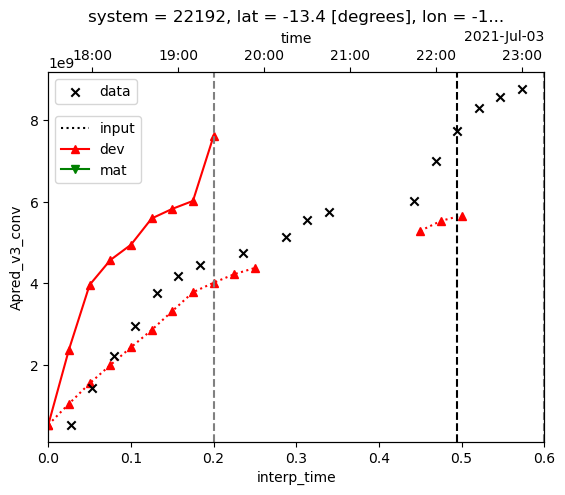

In [122]:
i = 33
sidx = ds.isel(system=i).system

fig, ax = plt.subplots()

axt = ax.twiny()
ds.isel(system=i).Apred_v3_conv.plot.scatter(ax=axt, c='k', marker='x', label="data")
axt.axvline(ds.isel(system=i).cloud_depth.idxmax('time').values, c='k', ls='--')
ax.plot([],[], ls=':', c='k', label='input')
developing.Apred_v3_conv.isel(system=i).plot(ax=ax, c='r', ls=':', marker='^')
mature.Apred_v3_conv.isel(system=i).plot(ax=ax, c='g', ls=':', marker='v')
# decay.Apred_v3_conv.isel(system=i).plot(ax=ax, c='b', ls=':')

# dev_intp.sel(system=sidx).Apred_v3_conv.plot(ax=ax, c='r', label='dev', marker='^')

show = results.isel(system=i)
show.Apred_v3_conv.sel(phase='developing').plot(ax=ax, c='r', label='dev', marker='^')
show.Apred_v3_conv.sel(phase='mature').plot(ax=ax, c='g', label='mat', marker='v')
# show.Apred_v3_conv.sel(phase='decay').plot(ax=ax, c='b', label='dec')

ax.axvline(0.2, ls='--', c='grey')
ax.axvline(0.6, ls='--', c='grey')

ax.set(title='')
axt.legend(bbox_to_anchor=(0,1), loc='upper left')
ax.legend(bbox_to_anchor=(0,.9), loc='upper left')

ax.set(xlim=(0,.6))

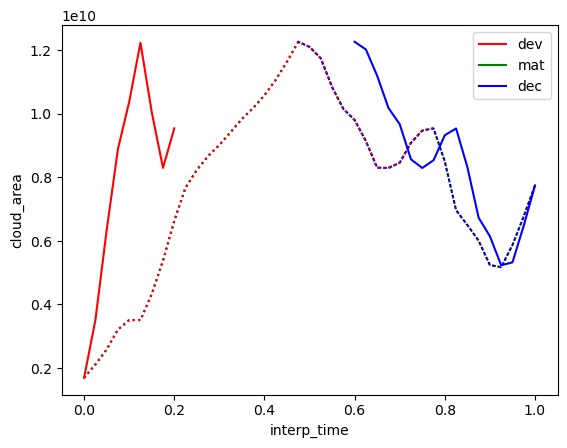

In [123]:
fig, ax = plt.subplots()

dsi.isel(system=i).cloud_area.plot(ax=ax, c='k', ls=':')
developing.cloud_area.isel(system=i).plot(ax=ax, c='r', ls=':')
mature.cloud_area.isel(system=i).plot(ax=ax, c='g', ls=':')
decay.cloud_area.isel(system=i).plot(ax=ax, c='b', ls=':')

show = results.isel(system=i)
show.cloud_area.sel(phase='developing').plot(ax=ax, c='r', label='dev')
show.cloud_area.sel(phase='mature').plot(ax=ax, c='g', label='mat')
show.cloud_area.sel(phase='decay').plot(ax=ax, c='b', label='dec')

ax.set(title='')
ax.legend()

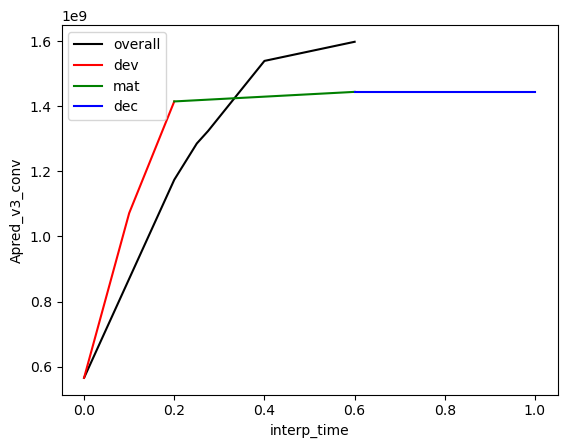

In [125]:
fig, ax = plt.subplots()

valid = results.where((results>0).any('interp_time').all('phase'))
valid = valid.Apred_v3_conv.mean('system')

valid.sel(phase='overall').plot(ax=ax, c='k', label='overall')
valid.sel(phase='developing').plot(ax=ax, c='r', label='dev')
valid.sel(phase='mature').plot(ax=ax, c='g', label='mat')
valid.sel(phase='decay').plot(ax=ax, c='b', label='dec')

ax.set(title='')
ax.legend()

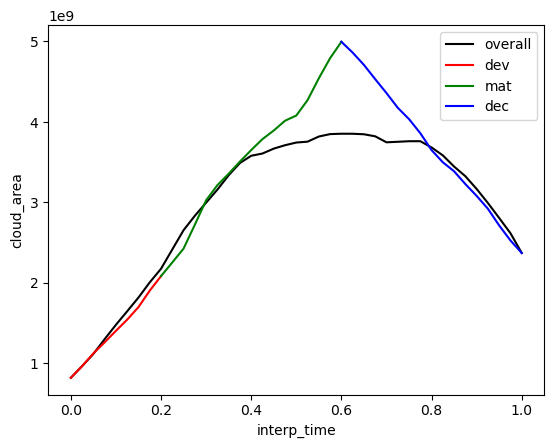

In [124]:
fig, ax = plt.subplots()

valid = results.where((results>0).any('interp_time').all('phase'))
valid = valid.cloud_area.mean('system')

valid.sel(phase='overall').plot(ax=ax, c='k', label='overall')
valid.sel(phase='developing').plot(ax=ax, c='r', label='dev')
valid.sel(phase='mature').plot(ax=ax, c='g', label='mat')
valid.sel(phase='decay').plot(ax=ax, c='b', label='dec')

ax.set(title='')
ax.legend()

#### OLD

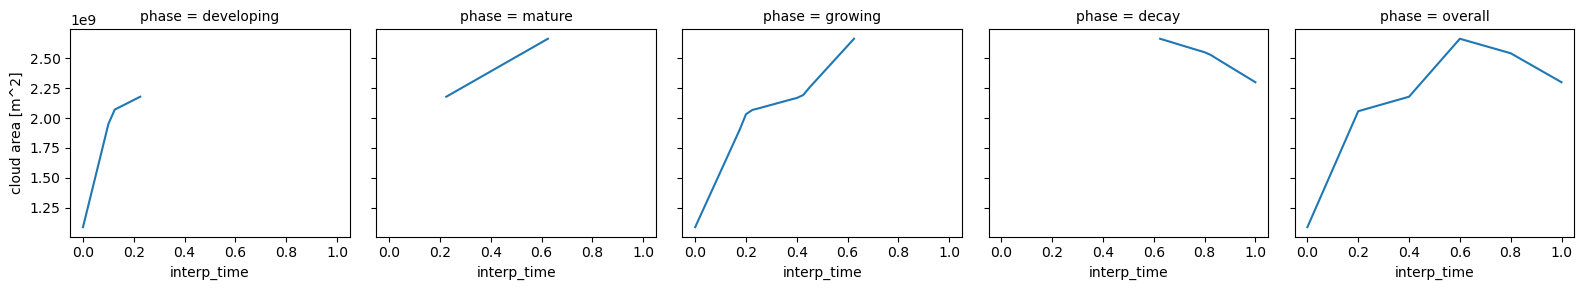

In [4]:
results.cloud_area.isel(system=7).plot(col='phase')

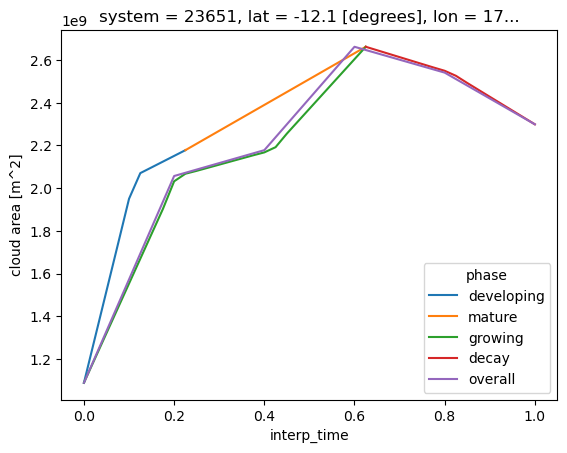

In [5]:
results.cloud_area.isel(system=7).plot(hue='phase')

In [31]:
# interpolate the full cloud evolution
tstep = 0.025
result = tools.normalise_by_lifetime(ds.cloud_area > 0, 
                                     ds[['cloud_area','anvil_area','cloud_depth']], 
                                     bins=np.arange(0, 1.025, tstep))
result = result.set_coords("interp_time")

# find the split points of the cloud evolution
t_max_depth = result.cloud_depth.idxmax('interp_time')
t_max_area = result.cloud_area.idxmax('interp_time')

# split the data by the corresponding phase
buff = 1
tdelta = tstep * buff
developing = result.where(result.interp_time <= t_max_depth+tdelta-tstep)
mature = result.where(np.logical_and(result.interp_time > t_max_depth-tdelta, 
                                     result.interp_time <= t_max_area+tdelta-tstep))
growing = result.where(result.interp_time <= t_max_area+tdelta-tstep)
decay = result.where(result.interp_time > t_max_area-tdelta)


In [82]:
t_max_depth

<xarray.DataArray 'interp_time' (system: 50)> Size: 400B
array([0.475, 0.05 , 0.375, 0.3  , 0.1  , 0.175, 0.325, 0.4  , 0.075,
       0.05 , 0.25 , 0.075, 0.75 , 0.375, 0.3  , 0.275, 0.425, 0.225,
       0.1  , 0.125, 0.625, 0.2  , 0.175, 0.2  , 0.275, 0.4  , 0.325,
       0.25 , 0.2  , 0.225, 0.25 , 0.25 , 0.5  , 0.775, 0.   , 0.   ,
       0.15 , 0.15 , 0.15 , 0.   , 0.2  , 0.25 , 0.175, 0.225, 0.125,
       0.25 , 0.75 , 0.2  , 0.425, 0.225])
Coordinates:
    lat         (system) float64 400B -4.9 -7.7 -0.9 3.4 ... 5.5 4.4 -12.8 13.4
    lon         (system) float64 400B 84.6 60.9 11.8 88.6 ... 122.4 116.5 144.2
    level_full  (system) int32 200B 61 59 63 63 61 63 61 ... 63 62 67 62 64 63
  * system      (system) int64 400B 6389 42 22572 8486 ... 12715 38975 20246

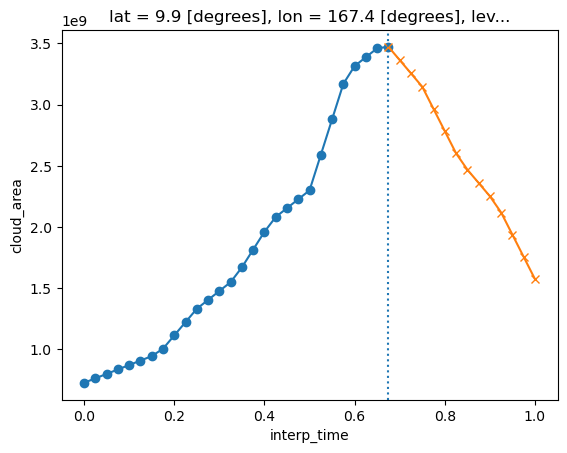

In [46]:
i = 6
growing.isel(system=i).cloud_area.plot(marker='o')
decay.isel(system=i).cloud_area.plot(marker='x')
plt.axvline(t_max_area.isel(system=i), ls=':')

In [67]:
d1 = growing.isel(system=i).cloud_area
d2 = decay.isel(system=i).cloud_area

In [79]:
def interpolate_time(data, new_t):
    # current growing times
    data = data.dropna('interp_time', how='all')
    t = data.interp_time
    
    # interpolate data on time axis t
    func = scipy.interpolate.PchipInterpolator(t, data)
    
    # make mapping from new_t to t
    imaginary_vals = (new_t - new_t.min()) / (new_t.max() - new_t.min()) * (t.max() - t.min()) + t.min()

    # evaluate values
    new_vals = func(imaginary_vals)
    
    return new_vals

interp_d1 = interpolate_time(d1, interp_grid[0:n_mat])
interp_d2 = interpolate_time(d2, interp_grid[n_mat:])

In [87]:
d = ds.isel(system=i)
t_max_area = d.cloud_area.idxmax('time')
d1 = d.where(d.time <= t_max_area).cloud_area
d2 = d.where(d.time >= t_max_area).cloud_area

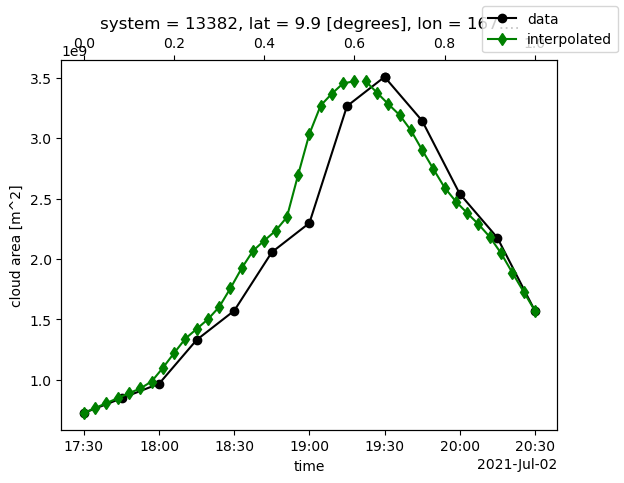

In [88]:

fig, ax = plt.subplots()
d1.plot(ax=ax, marker='o', c='k', label='data')
d2.plot(ax=ax, marker='o', c='k')
ax2 = ax.twiny()
ax2.plot(interp_grid[0:n_mat], interp_d1, marker='d', c='g', label='interpolated')
ax2.plot(interp_grid[n_mat:], interp_d2, marker='d', c='g')
fig.legend()

In [40]:
# find the transition points by which to align the results
tref_depth = 0.225 # hard code for consistency (chosen from mean of all systems)
tref_area = 0.625
interp_grid = result.interp_time
N = interp_grid.size
n_dev = int(N*tref_depth)
n_mat = int(N*tref_area)

import scipy

# apply that to each phase

# what t values would that corespond to?


def interp_phase(ds, new_time):
    data = ds.dropna('interp_time', how='all')
    t = data.interp_time
    if t.size <= 1:
        return ds.interp(interp_time=new_time)
    normalised = (
        (t - t.min()) / (t.max() - t.min())
        * (new_time.max() - new_time.min())
        + new_time.min()
    )
    return data.assign_coords(interp_time=normalised).interp(interp_time=new_time)

buff=1

# dev_intp = developing.groupby('system').map(interp_phase, args=(interp_grid[0:n_dev+buff-1],))
# mat_intp = mature.groupby('system').map(interp_phase, args=(interp_grid[n_dev-buff:n_mat+buff-1],))
# grow_intp = growing.groupby('system').map(interp_phase, args=(interp_grid[0:n_mat+buff-1],))
# dec_intp = decay.groupby('system').map(interp_phase, args=(interp_grid[n_mat-buff:],))

# buff=1

# phase_results = xr.concat([
#     dev_intp.isel(interp_time=slice(None,-buff+1)).expand_dims(phase=['developing']),
#     mat_intp.isel(interp_time=slice(buff,-buff+1)).expand_dims(phase=['mature']),
#     grow_intp.isel(interp_time=slice(None,-buff+1)).expand_dims(phase=['growing']),
#     dec_intp.isel(interp_time=slice(buff,None)).expand_dims(phase=['decay']),
#     ], dim='phase')

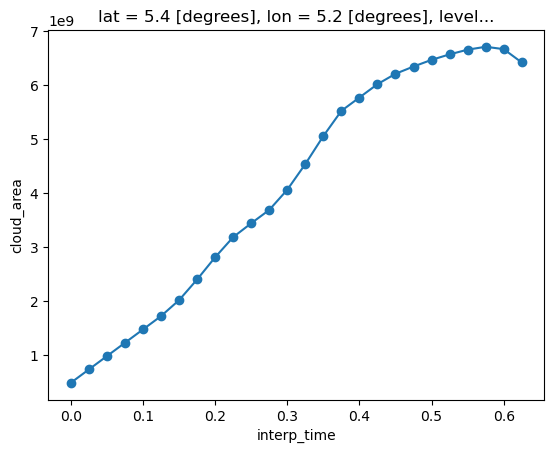

In [21]:
dev_intp.isel(system=i).cloud_area.plot(marker='o')

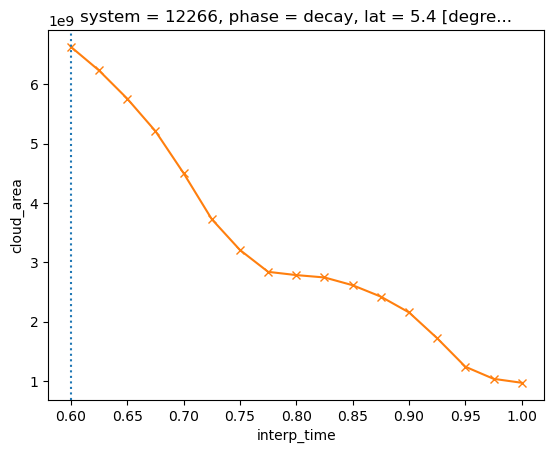

In [18]:
phase_results.sel(phase='growing').isel(system=i).cloud_area.plot(marker='o')
phase_results.sel(phase='decay').isel(system=i).cloud_area.plot(marker='x')
plt.axvline(.6, ls=':')


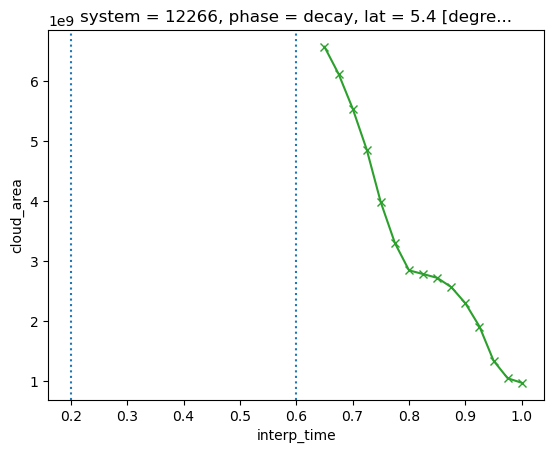

In [15]:
phase_results.sel(phase='developing').isel(system=i).cloud_area.plot(marker='o')
phase_results.sel(phase='mature').isel(system=i).cloud_area.plot(marker='d')
phase_results.sel(phase='decay').isel(system=i).cloud_area.plot(marker='x')
plt.axvline(.2, ls=':')
plt.axvline(.6, ls=':')

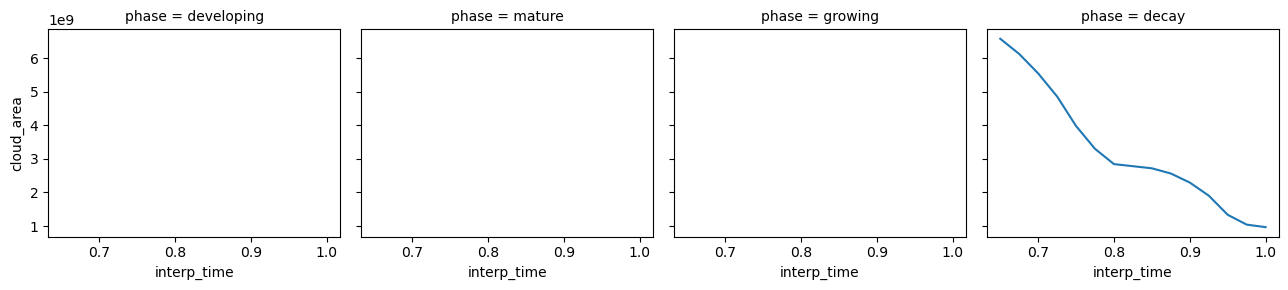

In [16]:
phase_results.cloud_area.isel(system=i).plot(col='phase')